# Proyecto Snake: agente de búsqueda heurística

**Representación y Solución Automática de Problemas**
Matemáticas Aplicadas y Ciencias de la Computación
Escuela de Ingeniería, Ciencia y Tecnología, Universidad del Rosario

**Autores:** Daniel José Morales y Juan Esteban Torres

**Contenido**
1. Descripción del entorno y formalización
2. Aplicación interactiva SnakeLab Studio
3. Instancia del entorno, algoritmos y heurísticas
4. Efecto del chequeo de seguridad
5. Evaluación experimental en 100 partidas
6. Variantes de mayor complejidad
7. Conclusiones

---
## 1. Descripción del entorno y formalización

Snake se juega en una cuadrícula de $N \times N$ celdas $(x, y) \in \{0, \dots, N-1\}^2$, con $N = 10$ en la versión base. Una serpiente recorre el tablero comiendo frutas y crece una celda con cada una. La partida se pierde si la serpiente choca contra un borde, un obstáculo o su propio cuerpo, y se gana cuando el cuerpo ocupa todas las celdas libres.

A nivel de partida el entorno es estocástico, porque cada fruta nueva aparece en una celda libre elegida al azar. Mientras una fruta permanece en el tablero, en cambio, no hay ninguna incertidumbre. Por eso el proyecto descompone la partida en una secuencia de subproblemas deterministas de búsqueda, uno por fruta, que resuelve un agente basado en modelo y basado en objetivos.

### Caracterización del entorno

| Propiedad | Clasificación | |
| :--- | :--- | :--- |
| Observabilidad | Completamente observable | El agente conoce el cuerpo completo, la fruta y los obstáculos. |
| Número de agentes | Un agente | En la variante adversaria un segundo agente coloca la fruta y el entorno pasa a ser multiagente. |
| Determinismo | Determinista por subproblema, estocástico por partida | La única fuente de azar es la posición de la siguiente fruta. |
| Episódico o secuencial | Secuencial | Cada movimiento cambia la forma del cuerpo y condiciona las decisiones futuras. |
| Estático o dinámico | Estático | El juego avanza por turnos y el tablero no cambia mientras el agente decide. |
| Discreto o continuo | Discreto | Las posiciones, las acciones y el tiempo son discretos. |
| Conocido o desconocido | Conocido | Las reglas de transición están implementadas en `ambientes.py` y el agente las usa para simular sus planes. |

### Formalización del problema

**Estados.** Un estado es la tupla $s = (C, f)$, implementada en la clase `EstadoSnake`. $C = (c_1, c_2, \dots, c_L)$ es la secuencia ordenada de celdas del cuerpo, con $c_1$ la cabeza, $c_L$ la cola y $L = |C|$ la longitud. $f \in \{0, \dots, N-1\}^2 \setminus C$ es la posición de la fruta, que tampoco puede coincidir con un obstáculo fijo.

**Acciones.** $\mathcal{A} = \{\text{norte}, \text{sur}, \text{este}, \text{oeste}\}$, con desplazamientos $\delta(a) \in \{(0,1), (0,-1), (1,0), (-1,0)\}$. Una acción es aplicable en $s$ si la nueva cabeza $h' = c_1 + \delta(a)$ queda dentro del tablero, o se envuelve de forma modular en la variante toroidal, y no coincide con un obstáculo ni con los segmentos $c_1, \dots, c_{L-1}$. La celda de la cola $c_L$ sí es válida cuando $L > 2$, porque la cola se mueve en el mismo turno. Como el giro de $180^\circ$ hacia el cuello $c_2$ nunca es aplicable, el factor de ramificación es $b \le 3$.

**Función de transición.** Si $a$ es aplicable y lleva la cabeza a $h'$:
1. Si $h' \neq f$, el cuerpo avanza y la cola libera su celda: $C' = (h', c_1, \dots, c_{L-1})$ y $f' = f$.
2. Si $h' = f$, la serpiente crece sin mover la cola: $C' = (h', c_1, \dots, c_L)$, y aparece una fruta $f'$ en una celda libre elegida de forma uniforme, o elegida por el oponente Minimax en la variante adversaria.

**Costo por paso.** Cada movimiento cuesta

$$c(s, a, s') = 1 + \lambda \, r(h'), \qquad r(h') = \frac{\text{vecinos bloqueados}(h')}{3} \in [0, 1],$$

donde $\text{vecinos bloqueados}(h') \in \{0, 1, 2, 3\}$ cuenta cuántas de las tres direcciones de avance desde $h'$ están ocupadas por el cuerpo, un obstáculo o el borde, y $\lambda \ge 0$ controla la aversión al riesgo. Con $\lambda = 0$ el costo de un camino es su número de pasos.

**Recompensa.** En cada turno, `Snake.step()` devuelve la recompensa

$$R(s, a, s') = \begin{cases} +1000 - c(s,a,s') & \text{si se come la última fruta y el tablero queda lleno} \\ +100 - c(s,a,s') & \text{si se come una fruta} \\ -100 - c(s,a,s') & \text{si } s' \text{ no tiene acciones aplicables} \\ -100 - c(s,a,s') & \text{si se completan } k_{\max} \text{ pasos sin comer} \\ -c(s,a,s') & \text{en cualquier otro movimiento} \end{cases}$$

Maximizar la recompensa acumulada $G = \sum_t R_t$ equivale a comer el mayor número de frutas con la menor cantidad de pasos y de riesgo.

**Objetivos y estados terminales.**
* **Objetivo de cada subproblema.** Llevar la cabeza hasta la fruta, $c_1 = f$, con el menor costo acumulado $g(n) = \sum c(s_i, a_i, s_{i+1})$, de modo que en el estado final siga existiendo un camino de la cabeza a la cola $c_L$. Este problema lo implementa `SubproblemaSnake`.
* **Objetivo de la partida.** Maximizar la longitud final $L_{\text{final}}$ y la recompensa $G$, idealmente hasta llenar el tablero.
* **Estados terminales.** La partida termina con una victoria cuando $L = N^2 - |\text{obstáculos}|$, con una derrota cuando $\mathcal{A}(s) = \emptyset$, o cuando pasan $k_{\max} = 200$ turnos seguidos sin comer.

In [11]:
# Configuración del entorno de trabajo e importación de los módulos.
import importlib
import sys
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

# En Google Colab se monta Drive y se usa la carpeta del proyecto allí.
# En Jupyter o VS Code se usa la carpeta local del notebook.
try:
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/Proyecto Representación")
except ImportError:
    CARPETA = Path.cwd()
sys.path.insert(0, str(CARPETA))

# Los módulos se importan después de ajustar sys.path y se recargan para
# tomar cualquier cambio en los archivos .py sin reiniciar el kernel.
import ambientes  # noqa: E402
import busqueda  # noqa: E402
import agentes  # noqa: E402
import utils  # noqa: E402
import interfaz  # noqa: E402

for modulo in (ambientes, busqueda, agentes, utils, interfaz):
    importlib.reload(modulo)

from ambientes import (  # noqa: E402
    Snake,
    SnakeJuegoAdversario,
    SubproblemaSnake,
)
from busqueda import (  # noqa: E402
    a_estrella,
    anchura,
    avara,
    busqueda_haz,
    comparar_algoritmos_en_instancia,
    dijkstra,
    heuristica_euclidea,
    heuristica_manhattan,
    heuristica_riesgo,
    profundidad,
    solucion,
)
from agentes import AgenteFrutaAdversaria, AgenteSnake  # noqa: E402
from utils import (  # noqa: E402
    EnvfromGameAndPl2,
    ejecutar_benchmark_completo,
    graficar_resultados_benchmark,
)
from interfaz import lanzar_aplicacion_snake  # noqa: E402

# Parámetro de aversión al riesgo usado en las demostraciones.
LAMBDA_RIESGO = 0.5


def jugar_partida(env, agente, semilla, max_pasos=2500):
    """Juega una partida completa de un agente en un entorno Snake.

    En cada turno el agente percibe el estado, decide una acción y el
    entorno la ejecuta, hasta que la partida termina o se alcanza
    ``max_pasos``.

    Parámetros
    ----------
    env : Snake
        Entorno en el que se juega la partida.
    agente : AgenteSnake
        Agente que toma las decisiones.
    semilla : int
        Semilla con la que se reinicia el entorno.
    max_pasos : int, opcional
        Número máximo de pasos antes de cortar la partida.

    Retorna
    -------
    Snake
        El mismo entorno, en su estado final.
    """
    estado = env.reset(semilla=semilla)
    agente.states.append(estado)
    while not env.done and env.pasos < max_pasos:
        estado, _, _ = env.step(agente.make_decision())
        agente.states.append(estado)
    return env


print("Módulos cargados correctamente.")

Módulos cargados correctamente.


---
## 2. Aplicación interactiva SnakeLab Studio

La celda siguiente ejecuta `lanzar_aplicacion_snake()` de `interfaz.py`, que inicia un servidor local dentro del kernel y muestra un enlace para abrir SnakeLab Studio en otra pestaña del navegador. En Colab el enlace pasa por `google.colab.output`. En Jupyter local la aplicación queda en `http://localhost:8050`, o en el siguiente puerto libre si ese está ocupado. La página, formada por `web/index.html`, `web/app.js` y `web/estilos.css`, llama directamente a las funciones de `ambientes.py`, `busqueda.py` y `agentes.py`, y se organiza en cinco pestañas:

1. **Búsqueda paso a paso.** Permite generar una instancia aleatoria o dibujarla sobre el tablero y reproducir la búsqueda iteración por iteración, mostrando nodos expandidos, frontera, nodo actual y $f(n) = g(n) + h(n)$.
2. **Comparar algoritmos.** Ejecuta los seis algoritmos y las tres heurísticas sobre la misma instancia y grafica nodos generados y expandidos, frontera máxima, tiempo y costo.
3. **Partida completa.** Reproduce una partida de `AgenteSnake` y señala los turnos en que actúa el chequeo de seguridad.
4. **Juega contra la IA.** Permite jugar manualmente y comparar el puntaje con el del agente.
5. **Resultados 100 semillas.** Resume el experimento de la Sección 5.

La interfaz se desarrolló con apoyo de IA generativa.

In [12]:
# Inicia el servidor local de SnakeLab Studio y muestra el enlace para
# abrir la aplicación en otra pestaña del navegador.
lanzar_aplicacion_snake()

---
## 3. Instancia del entorno, algoritmos y heurísticas

Se crea un entorno `Snake` de $10 \times 10$ con 8 obstáculos y semilla 7, y sobre su estado inicial se define un `SubproblemaSnake` con $\lambda = 0.5$. La celda muestra los métodos del espacio de estados, `estado_inicial`, `codigo`, `acciones_aplicables`, `test_objetivo`, `transicion` y `costo`, evalúa las heurísticas $h_1$ y $h_2$, resuelve el subproblema con `a_estrella` y dibuja el camino con `render`.

1. Estado inicial s = (C, f)  : EstadoSnake(cabeza=(5, 5), L=1, fruta=(8, 0))
2. Código codigo(s)           : 5-5
3. Acciones aplicables        : ['sur', 'oeste']
4. ¿Es estado objetivo?       : False
5. Transición con 'sur'       : EstadoSnake(cabeza=(5, 4), L=1, fruta=(8, 0))
6. Costo del paso c(s, a, s') : 1.000
7. Heurística h1, Manhattan   : 8.000
8. Heurística h2, euclídea    : 5.831
9. Solución con A*            : ['sur', 'sur', 'sur', 'sur', 'este', 'este', 'sur', 'este']


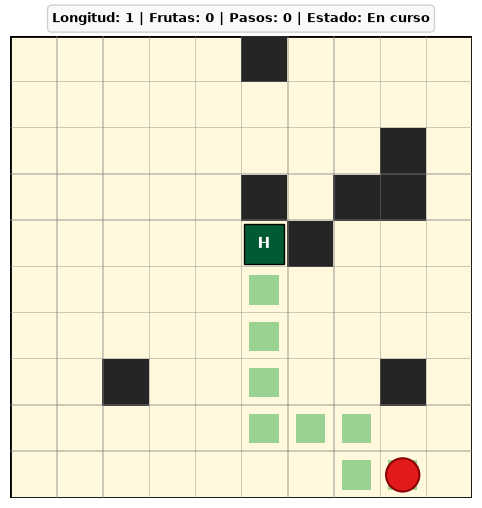

In [13]:
# Entorno de 10 x 10 con 8 obstáculos fijos y su estado inicial.
env_ejemplo = Snake(tamano=10, semilla=7, num_obstaculos=8,
                    lambda_riesgo=LAMBDA_RIESGO)
est_ejemplo = env_ejemplo.reset(semilla=7)

# Subproblema determinista: llevar la cabeza hasta la fruta actual.
prob_ejemplo = SubproblemaSnake(estado_inicial=est_ejemplo,
                                lambda_riesgo=LAMBDA_RIESGO)

# Métodos del espacio de estados evaluados en el estado inicial, junto
# con la transición y el costo de la primera acción aplicable.
acciones = prob_ejemplo.acciones_aplicables(est_ejemplo)
accion = acciones[0]
nodo_astar = a_estrella(prob_ejemplo, heuristica_manhattan)

demostracion = [
    ("Estado inicial s = (C, f)", prob_ejemplo.estado_inicial),
    ("Código codigo(s)", prob_ejemplo.codigo(est_ejemplo)),
    ("Acciones aplicables", acciones),
    ("¿Es estado objetivo?", prob_ejemplo.test_objetivo(est_ejemplo)),
    (f"Transición con '{accion}'",
     prob_ejemplo.transicion(est_ejemplo, accion)),
    ("Costo del paso c(s, a, s')",
     f"{prob_ejemplo.costo(est_ejemplo, accion):.3f}"),
    ("Heurística h1, Manhattan",
     f"{heuristica_manhattan(est_ejemplo):.3f}"),
    ("Heurística h2, euclídea", f"{heuristica_euclidea(est_ejemplo):.3f}"),
    ("Solución con A*", solucion(nodo_astar)),
]
for i, (etiqueta, valor) in enumerate(demostracion, start=1):
    print(f"{i}. {etiqueta:<27}: {valor}")

# Dibujo del camino encontrado por A*.
env_ejemplo.render(camino=prob_ejemplo.ultimo_resultado.camino_celdas)
plt.show()

### 3.1 Entorno secuencial `Snake` y función `step()`

`SubproblemaSnake` modela un único tramo, desde la posición actual hasta la fruta. `Snake` modela la partida completa: guarda el estado, los contadores y el balance de recompensas, y en cada turno `step(a)` devuelve la tupla $(s', R(s,a,s'), \text{done})$ con la recompensa definida en la Sección 1.

La primera celda imprime los atributos del entorno y del estado $s = (C, f)$. La segunda llama a `step()` a mano siguiendo el plan de A* hasta comer la primera fruta y, al final, prueba una acción no aplicable para mostrar cómo el entorno la penaliza y termina el episodio.

In [14]:
# Entorno secuencial con la misma instancia de la celda anterior.
env_demo = Snake(tamano=10, semilla=7, num_obstaculos=8,
                 lambda_riesgo=LAMBDA_RIESGO, k_max=200)
s = env_demo.reset(semilla=7)

ATRIBUTOS_ENTORNO = [
    "tamano", "semilla", "toroidal", "num_obstaculos", "num_frutas",
    "lambda_riesgo", "k_max", "ganancia_fruta", "ganancia_victoria",
    "perdida_choque", "pasos", "frutas_comidas", "ganancia_total",
    "perdida_total", "done", "causa_fin",
]
ATRIBUTOS_ESTADO = [
    "cuerpo", "cabeza", "cola", "longitud", "fruta", "obstaculos",
    "tamano", "toroidal",
]

print("Atributos del entorno Snake")
for nombre in ATRIBUTOS_ENTORNO:
    print(f"  {nombre:<18} = {getattr(env_demo, nombre)}")

print("\nAtributos del estado EstadoSnake s = (C, f)")
for nombre in ATRIBUTOS_ESTADO:
    print(f"  {nombre:<18} = {getattr(s, nombre)}")

Atributos del entorno Snake
  tamano             = 10
  semilla            = 7
  toroidal           = False
  num_obstaculos     = 8
  num_frutas         = 1
  lambda_riesgo      = 0.5
  k_max              = 200
  ganancia_fruta     = 100.0
  ganancia_victoria  = 1000.0
  perdida_choque     = 100.0
  pasos              = 0
  frutas_comidas     = 0
  ganancia_total     = 0.0
  perdida_total      = 0.0
  done               = False
  causa_fin          = En curso

Atributos del estado EstadoSnake s = (C, f)
  cuerpo             = ((5, 5),)
  cabeza             = (5, 5)
  cola               = (5, 5)
  longitud           = 1
  fruta              = (8, 0)
  obstaculos         = ((7, 6), (8, 2), (2, 2), (8, 6), (5, 6), (5, 9), (6, 5), (8, 7))
  tamano             = 10
  toroidal           = False


,acción,cabeza c1,longitud L,"R(s,a,s')",done,frutas_comidas,ganancia_total,perdida_total,causa_fin
t,,,,,,,,,
1,sur,"(5, 4)",1,-1.000,False,0,0.0,1.000,En curso
2,sur,"(5, 3)",1,-1.000,False,0,0.0,2.000,En curso
3,sur,"(5, 2)",1,-1.000,False,0,0.0,3.000,En curso
4,sur,"(5, 1)",1,-1.000,False,0,0.0,4.000,En curso
5,este,"(6, 1)",1,-1.000,False,0,0.0,5.000,En curso
6,este,"(7, 1)",1,-1.000,False,0,0.0,6.000,En curso
7,sur,"(7, 0)",1,-1.167,False,0,0.0,7.167,En curso
8,este,"(8, 0)",2,98.833,False,1,100.0,8.333,En curso


Recompensa acumulada G = ΣR = 91.666 = ganancia_total - perdida_total = 100.000 - 8.333

step('sur') no aplicable -> R = -100.0, done = True, causa_fin = 'Colisión / Acción inválida (sur)'


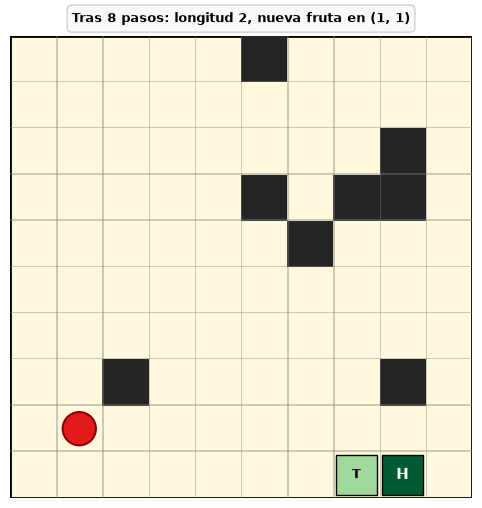

In [15]:
# Plan óptimo hasta la primera fruta, calculado con A* y h1.
prob_demo = SubproblemaSnake(estado_inicial=s, lambda_riesgo=LAMBDA_RIESGO)
plan = solucion(a_estrella(prob_demo, heuristica_manhattan))

# Se ejecuta step() a mano y se registra (s', R, done) en cada turno.
filas = []
for t, accion in enumerate(plan, start=1):
    s, recompensa, done = env_demo.step(accion)
    filas.append({
        "t": t,
        "acción": accion,
        "cabeza c1": s.cabeza,
        "longitud L": s.longitud,
        "R(s,a,s')": round(recompensa, 3),
        "done": done,
        "frutas_comidas": env_demo.frutas_comidas,
        "ganancia_total": env_demo.ganancia_total,
        "perdida_total": round(env_demo.perdida_total, 3),
        "causa_fin": env_demo.causa_fin,
    })
tabla_step = pd.DataFrame(filas).set_index("t")
display(tabla_step)

# La suma de recompensas coincide con el balance de ganancias y
# pérdidas.
retorno = tabla_step["R(s,a,s')"].sum()
print(f"Recompensa acumulada G = ΣR = {retorno:.3f} = "
      f"ganancia_total - perdida_total = "
      f"{env_demo.ganancia_total:.3f} - {env_demo.perdida_total:.3f}")

# Una acción no aplicable se trata como colisión y termina el episodio.
# Se usa una copia del entorno para no alterar env_demo.
env_choque = deepcopy(env_demo)
invalidas = [a for a in ("norte", "sur", "este", "oeste")
             if a not in env_choque.acciones_aplicables()]
_, r_choque, done_choque = env_choque.step(invalidas[0])
print(f"\nstep('{invalidas[0]}') no aplicable -> R = {r_choque}, "
      f"done = {done_choque}, causa_fin = '{env_choque.causa_fin}'")

# Tablero después de comer la primera fruta.
env_demo.render(titulo=(f"Tras {env_demo.pasos} pasos: longitud "
                        f"{s.longitud}, nueva fruta en {s.fruta}"))
plt.show()

### 3.2 Los seis algoritmos sobre la misma instancia

Se aplican las seis funciones de búsqueda de `busqueda.py`, `anchura`, `profundidad`, `dijkstra`, `avara`, `a_estrella` y `busqueda_haz`, sobre la instancia de la Sección 3. En cada tablero el camino encontrado aparece en verde y las celdas expandidas en azul.

La tabla siguiente, generada con `comparar_algoritmos_en_instancia`, reúne las métricas de cada algoritmo con cada heurística aplicable e indica si la solución alcanza el costo óptimo. Como $\lambda = 0.5$, BFS minimiza el número de pasos pero no necesariamente el costo.

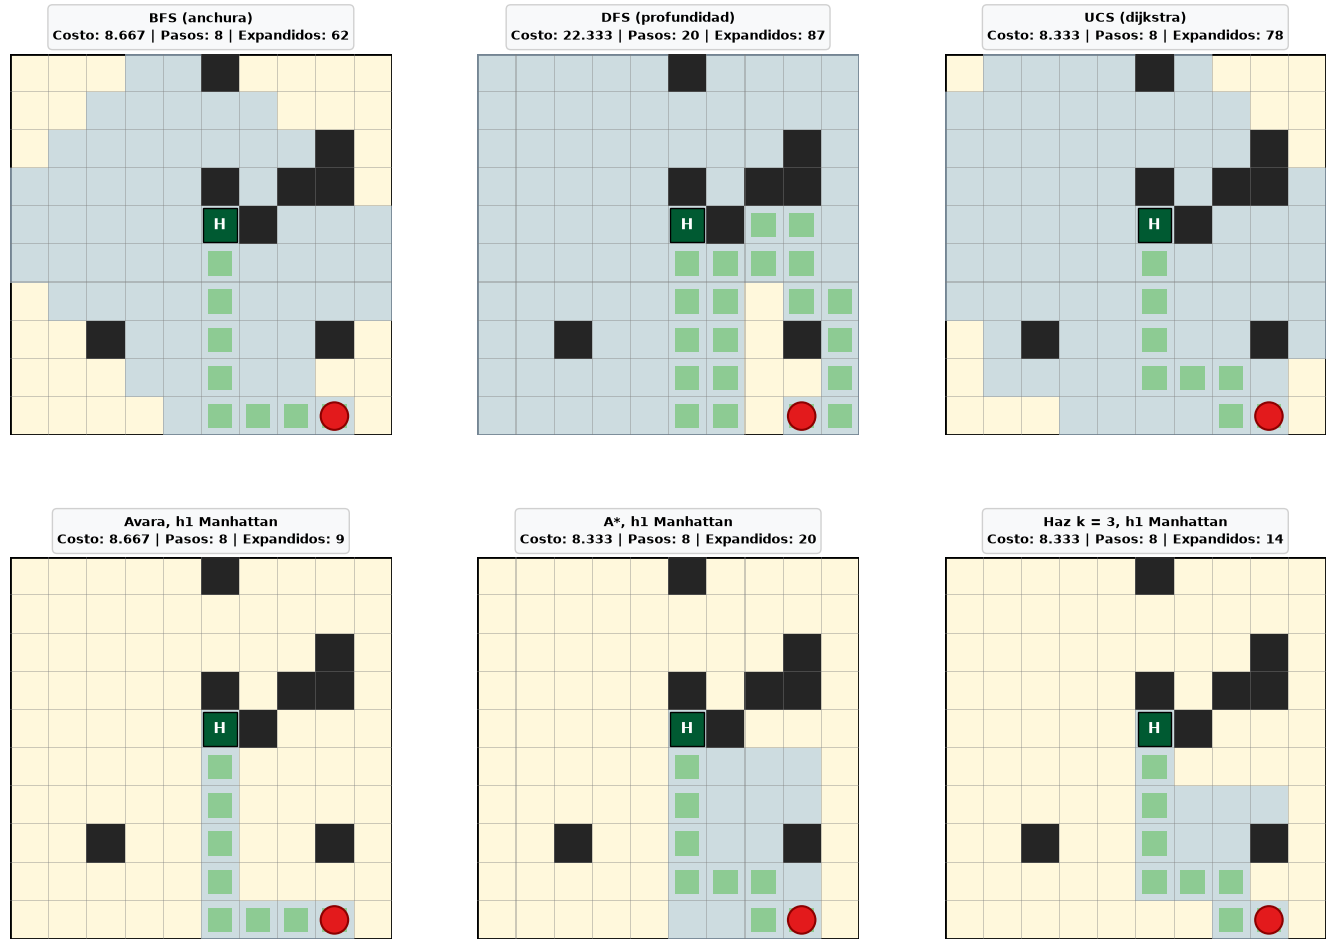

,Algoritmo,Heurística,Éxito,Costo g,Pasos,Nodos generados,Nodos expandidos,Frontera máx.,Tiempo (ms),¿Óptimo?
0,BFS,ninguna,True,8.667,8,75,62,18,2.528,False
1,DFS,ninguna,True,22.333,20,146,87,61,1.976,False
2,UCS,ninguna,True,8.333,8,87,78,21,1.793,True
3,Avara,manhattan,True,8.667,8,20,9,12,0.459,False
4,Avara,euclidea,True,8.333,8,19,9,11,0.614,True
5,Avara,riesgo,True,8.333,8,21,9,13,1.118,True
6,A*,manhattan,True,8.333,8,33,20,14,0.989,True
7,A*,euclidea,True,8.333,8,35,23,13,0.926,True
8,A*,riesgo,True,8.333,8,32,20,15,0.855,True
9,Beam(k=3),manhattan,True,8.333,8,27,14,3,0.597,True


In [16]:
# Cada entrada asocia un nombre con la llamada al algoritmo. Con
# guardar_traza=True se conservan las celdas expandidas para dibujarlas.
ALGORITMOS = [
    ("BFS (anchura)",
     lambda p: anchura(p, guardar_traza=True)),
    ("DFS (profundidad)",
     lambda p: profundidad(p, guardar_traza=True)),
    ("UCS (dijkstra)",
     lambda p: dijkstra(p, guardar_traza=True)),
    ("Avara, h1 Manhattan",
     lambda p: avara(p, heuristica_manhattan, guardar_traza=True)),
    ("A*, h1 Manhattan",
     lambda p: a_estrella(p, heuristica_manhattan, guardar_traza=True)),
    ("Haz k = 3, h1 Manhattan",
     lambda p: busqueda_haz(p, heuristica_manhattan, k=3,
                            guardar_traza=True)),
]

fig, axes = plt.subplots(2, 3, figsize=(17, 11.5),
                         gridspec_kw={"hspace": 0.32, "wspace": 0.22})
for ax, (nombre, algoritmo) in zip(axes.flat, ALGORITMOS):
    # Cada algoritmo recibe un subproblema nuevo para no mezclar
    # métricas.
    prob = SubproblemaSnake(estado_inicial=est_ejemplo,
                            lambda_riesgo=LAMBDA_RIESGO)
    nodo = algoritmo(prob)
    res = prob.ultimo_resultado
    expandidos = res.traza[-1].expandidos_celdas if res.traza else None
    titulo = (f"{nombre}\nCosto: {res.costo_total:.3f} | "
              f"Pasos: {len(solucion(nodo))} | "
              f"Expandidos: {res.nodos_expandidos}")
    env_ejemplo.render(estado=est_ejemplo, camino=res.camino_celdas,
                       expandidos=expandidos, ax=ax, titulo=titulo)
plt.show()

# Métricas de los seis algoritmos con cada heurística aplicable.
resultados = comparar_algoritmos_en_instancia(est_ejemplo,
                                              lambda_riesgo=LAMBDA_RIESGO)
tabla_algoritmos = pd.DataFrame([{
    "Algoritmo": r.algoritmo,
    "Heurística": r.heuristica,
    "Éxito": r.exito,
    "Costo g": round(r.costo_total, 3),
    "Pasos": r.longitud_solucion,
    "Nodos generados": r.nodos_generados,
    "Nodos expandidos": r.nodos_expandidos,
    "Frontera máx.": r.max_frontera,
    "Tiempo (ms)": round(r.tiempo_ms, 3),
    "¿Óptimo?": r.es_optimo,
} for r in resultados])
display(tabla_algoritmos)

### 3.3 Comparación de las heurísticas $h_1$, $h_2$ y $h_3$

`busqueda.py` define tres heurísticas. $h_1$ es la distancia Manhattan entre la cabeza y la fruta, $h_2$ es la distancia euclídea y $h_3 = h_1 + 2\,r(c_1)$ suma una penalización por el riesgo de encierro alrededor de la cabeza. Como cada paso cuesta al menos 1 y mueve la cabeza una sola celda, $h_1$ nunca sobreestima el costo real y es admisible. $h_2 \le h_1$, así que también lo es. $h_3$, en cambio, puede sobreestimarlo.

Para comprobarlo de forma empírica se juega una partida con el agente completo, se toma una muestra de los estados visitados y en cada uno se compara $h(s)$ con el costo óptimo real $h^*(s)$, calculado con `dijkstra`. También se registra cuántos nodos expande `a_estrella` con cada heurística y si su solución es óptima.

,estados,h_promedio,h_estrella_promedio,pct_admisible,nodos_expandidos_A,pct_A_optimo
Heurística,,,,,,
h₁ Manhattan,30,5.23,5.6,100.00,10.90,100.0
h₂ Euclídea,30,4.31,5.6,100.00,12.23,100.0
h₃ Riesgo,30,5.46,5.6,73.33,10.80,100.0


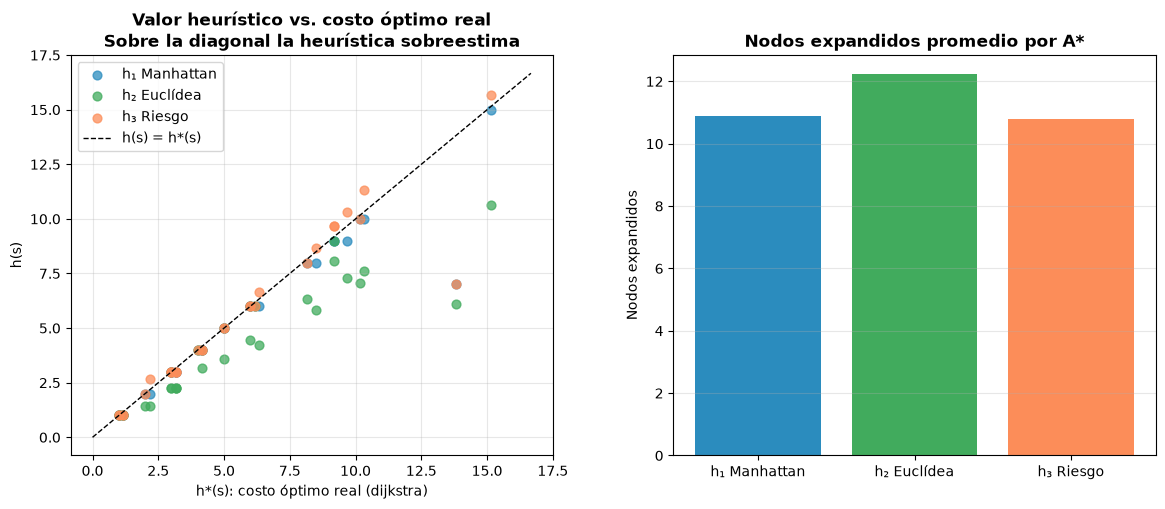

In [17]:
# Heurísticas comparadas y color asignado a cada una en las gráficas.
HEURISTICAS = {
    "h₁ Manhattan": heuristica_manhattan,
    "h₂ Euclídea": heuristica_euclidea,
    "h₃ Riesgo": heuristica_riesgo,
}
COLORES = {
    "h₁ Manhattan": "#2b8cbe",
    "h₂ Euclídea": "#41ab5d",
    "h₃ Riesgo": "#fc8d59",
}

# 1. Se juega una partida con el agente completo y se guardan los
#    estados que tienen fruta en el tablero. Se toma uno de cada
#    cinco.
env_h = Snake(tamano=10, semilla=1, k_max=200, lambda_riesgo=LAMBDA_RIESGO)
ag_h = AgenteSnake(algoritmo="A*", heuristica="manhattan",
                   chequeo_seguridad=True, lambda_riesgo=LAMBDA_RIESGO)
s_h = env_h.reset(semilla=1)
ag_h.states.append(s_h)
estados_muestra = []
while not env_h.done and len(estados_muestra) < 150:
    if s_h.fruta is not None:
        estados_muestra.append(s_h)
    s_h, _, _ = env_h.step(ag_h.make_decision())
    ag_h.states.append(s_h)
estados_muestra = estados_muestra[::5]

# 2. En cada estado se calcula el costo óptimo real h*(s) con
#    Dijkstra y se compara con h(s) y con el resultado de A* para
#    cada heurística.
filas = []
for s_i in estados_muestra:
    prob = SubproblemaSnake(estado_inicial=s_i, lambda_riesgo=LAMBDA_RIESGO)
    if dijkstra(prob) is None:
        continue  # Sin camino a la fruta no hay h*(s) con qué comparar.
    h_estrella = prob.ultimo_resultado.costo_total
    for nombre, fn_h in HEURISTICAS.items():
        prob_a = SubproblemaSnake(estado_inicial=s_i,
                                  lambda_riesgo=LAMBDA_RIESGO)
        a_estrella(prob_a, fn_h)
        res = prob_a.ultimo_resultado
        h_s = fn_h(s_i)
        filas.append({
            "Heurística": nombre,
            "h(s)": h_s,
            "h*(s)": h_estrella,
            "Admisible en s": h_s <= h_estrella + 1e-9,
            "Nodos expandidos A*": res.nodos_expandidos,
            "Costo A*": res.costo_total,
            "A* óptimo": abs(res.costo_total - h_estrella) < 1e-6,
        })
df_h = pd.DataFrame(filas)

# 3. Resumen por heurística.
resumen_h = df_h.groupby("Heurística").agg(
    estados=("h(s)", "size"),
    h_promedio=("h(s)", "mean"),
    h_estrella_promedio=("h*(s)", "mean"),
    pct_admisible=("Admisible en s", lambda x: 100 * x.mean()),
    nodos_expandidos_A=("Nodos expandidos A*", "mean"),
    pct_A_optimo=("A* óptimo", lambda x: 100 * x.mean()),
).round(2)
display(resumen_h)

# 4. Gráficas: h(s) frente a h*(s) y nodos expandidos promedio por A*.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2),
                         gridspec_kw={"wspace": 0.25})
lim = max(df_h["h(s)"].max(), df_h["h*(s)"].max()) + 1
for nombre, grupo in df_h.groupby("Heurística"):
    axes[0].scatter(grupo["h*(s)"], grupo["h(s)"], label=nombre,
                    color=COLORES[nombre], alpha=0.75, s=40)
axes[0].plot([0, lim], [0, lim], "k--", lw=1, label="h(s) = h*(s)")
axes[0].set_title("Valor heurístico vs. costo óptimo real\n"
                  "Sobre la diagonal la heurística sobreestima",
                  weight="bold")
axes[0].set_xlabel("h*(s): costo óptimo real (dijkstra)")
axes[0].set_ylabel("h(s)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(resumen_h.index, resumen_h["nodos_expandidos_A"],
            color=[COLORES[n] for n in resumen_h.index])
axes[1].set_title("Nodos expandidos promedio por A*", weight="bold")
axes[1].set_ylabel("Nodos expandidos")
axes[1].grid(axis="y", alpha=0.3)
plt.show()

---
## 4. Efecto del chequeo de seguridad

Se juegan dos partidas con la misma semilla y el mismo agente A* con $h_1$. La única diferencia es el chequeo de seguridad. Sin él, el agente sigue siempre el camino más corto hasta la fruta. Con él, antes de ejecutar un plan simula el estado que quedaría después de comer y verifica con BFS que la cabeza todavía pueda llegar a la cola $c_L$. Si no puede, da un paso de evasión siguiendo su cola y vuelve a planear. Esta lógica está en `AgenteSnake.program()`.

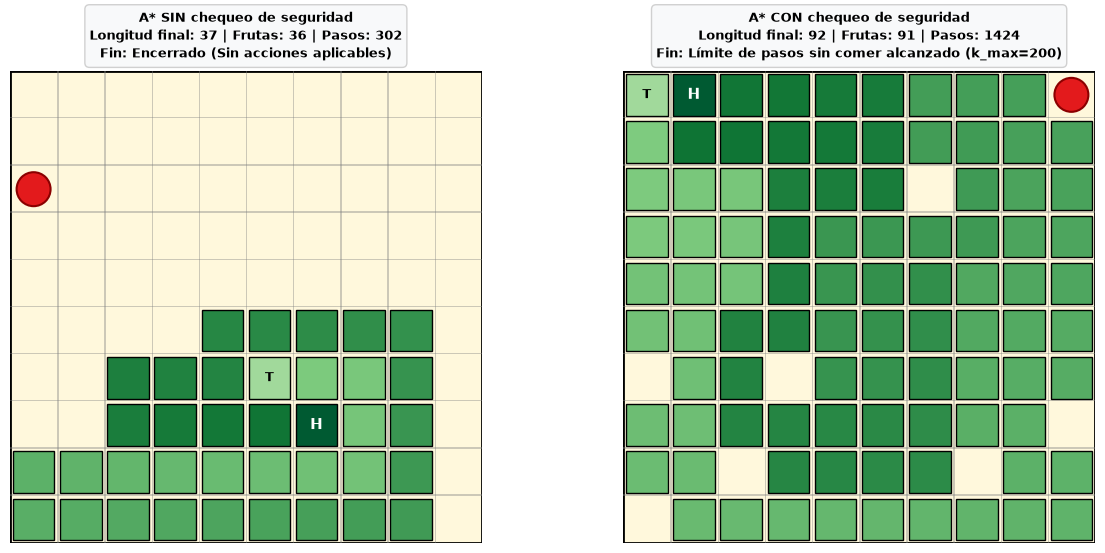

In [18]:
# Ambos agentes juegan con la misma semilla; solo cambia el chequeo.
SEMILLA_CHEQUEO = 0

fig, axes = plt.subplots(1, 2, figsize=(14, 6.2),
                         gridspec_kw={"wspace": 0.30})
for ax, usar_seguridad in zip(axes, (False, True)):
    env_c = Snake(tamano=10, semilla=SEMILLA_CHEQUEO, k_max=200)
    ag_c = AgenteSnake(algoritmo="A*", heuristica="manhattan",
                       chequeo_seguridad=usar_seguridad)
    jugar_partida(env_c, ag_c, semilla=SEMILLA_CHEQUEO, max_pasos=3000)

    etiqueta = "CON" if usar_seguridad else "SIN"
    titulo = (f"A* {etiqueta} chequeo de seguridad\n"
              f"Longitud final: {env_c.estado.longitud} | "
              f"Frutas: {env_c.frutas_comidas} | Pasos: {env_c.pasos}\n"
              f"Fin: {env_c.causa_fin}")
    env_c.render(titulo=titulo, ax=ax)
plt.show()

---
## 5. Evaluación experimental en 100 partidas

Cada configuración juega las mismas 100 partidas, con semillas de 0 a 99, en un tablero de $10 \times 10$ sin obstáculos, con $k_{\max} = 200$ y un tope de 2500 pasos por partida. Se evalúan los seis algoritmos con y sin chequeo de seguridad, A* con $h_1$ y con $h_2$, y A* con $\lambda = 0$ y con $\lambda = 0.5$. Dijkstra se ejecuta con $\lambda = 0.5$, ya que con $\lambda = 0$ se comporta igual que BFS. En total son 14 configuraciones y 1400 partidas.

La función `ejecutar_benchmark_completo` de `utils.py` guarda todas las métricas en `resultados_benchmark_100_semillas.csv` y, si el archivo ya existe, lo carga en lugar de volver a jugar las partidas.

,algoritmo,heuristica,chequeo_seguridad,lambda_riesgo,Longitud_Prom,Longitud_Std,Longitud_Max,Victorias_Pct,Pasos_por_Fruta,Nodos_Gen_Prom,Nodos_Exp_Prom,Max_Frontera,Tiempo_Dec_ms,Recompensa_Prom
0,A*,euclidea,True,0.0,93.07,7.57,100,3.0,20.78,53.58,47.21,24.81,1.90,7212.32
1,A*,manhattan,False,0.0,34.85,9.05,59,0.0,8.09,29.19,20.65,22.34,0.97,3006.42
2,A*,manhattan,True,0.0,93.29,8.51,100,2.0,20.30,54.63,47.94,22.67,1.89,7258.23
3,A*,manhattan,True,0.5,91.05,7.22,100,2.0,20.73,54.59,46.87,26.55,2.71,6684.11
4,Avara,manhattan,False,0.0,34.13,8.62,58,0.0,8.19,21.75,12.84,23.43,0.97,2936.69
5,Avara,manhattan,True,0.0,93.51,9.40,100,7.0,19.99,52.04,43.80,24.13,1.73,7353.25
6,BFS,ninguna,False,0.0,34.17,8.31,55,0.0,8.00,44.35,37.42,18.11,0.88,2948.29
7,BFS,ninguna,True,0.0,91.54,12.06,100,8.0,19.09,57.30,50.65,18.28,1.09,7275.24
8,Beam,manhattan,False,0.0,34.73,9.69,65,0.0,8.25,26.11,16.09,6.99,0.71,2988.03
9,Beam,manhattan,True,0.0,92.26,8.79,100,1.0,20.10,51.05,42.31,16.47,1.62,7184.45


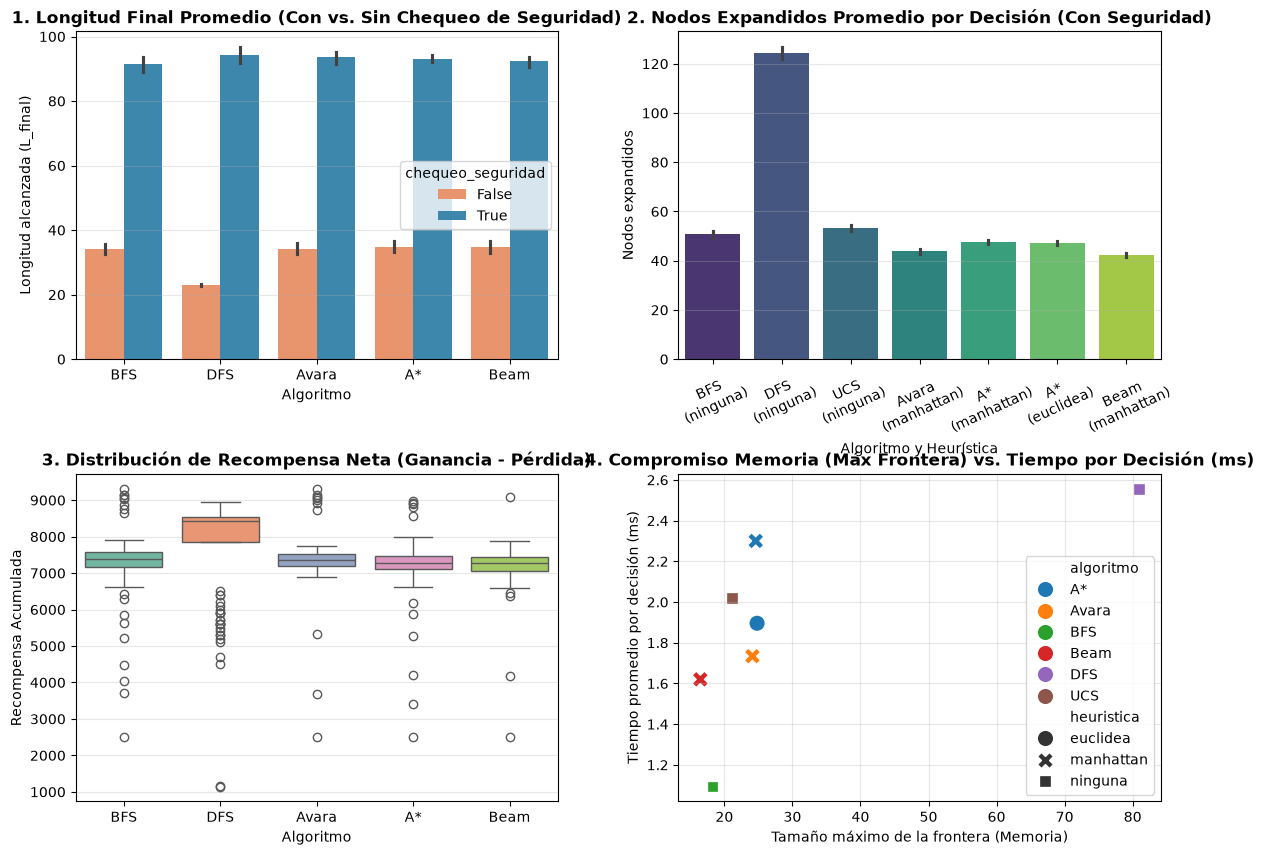

In [19]:
# Con RECALCULAR_BENCHMARK = True se vuelven a jugar las 1400 partidas,
# 14 configuraciones por 100 semillas, lo que tarda varios minutos.
# Con False se cargan los resultados guardados en el CSV.
RECALCULAR_BENCHMARK = False

ruta_csv = CARPETA / "resultados_benchmark_100_semillas.csv"
df_crudo, df_resumen = ejecutar_benchmark_completo(
    num_semillas=100,
    tamano=10,
    k_max=200,
    archivo_csv=str(ruta_csv),
    forzar_recalculo=RECALCULAR_BENCHMARK,
)

# Tabla resumen por configuración y gráficas comparativas.
display(df_resumen)
graficar_resultados_benchmark(df_crudo)

### Análisis de resultados

* **El chequeo de seguridad es el factor decisivo.** Sin él, las 600 partidas terminan con la serpiente encerrada y la longitud final media queda entre 32 y 35 para todos los algoritmos salvo DFS, que llega a 23. Con el chequeo sube a valores entre 91 y 94, y los encierros bajan a entre 2 y 10 partidas de cada 100.
* **La seguridad tiene un costo moderado.** Los pasos por fruta pasan de unos 8 a unos 20 y aumentan los nodos expandidos por decisión, porque cada decisión incluye la búsqueda hasta la cola. Aun así, ninguna configuración supera en promedio los 3 ms por decisión.
* **Hay pocas victorias.** Con el chequeo, entre el 82 % y el 92 % de las partidas terminan por $k_{\max}$. Con el tablero casi lleno, el agente descarta los caminos que lo encerrarían y se queda siguiendo su cola sin volver a comer. DFS es la excepción, con 75 victorias, porque sus caminos largos recorren el tablero de forma ordenada. Otras 23 de sus partidas llegan al tope de 2500 pasos sin terminar.
* **Heurísticas y costo por riesgo.** Sin chequeo, la búsqueda avara, el haz y A* expanden entre 13 y 21 nodos por decisión, frente a 37 de BFS y 45 de Dijkstra, sin perder longitud. Cambiar $h_1$ por $h_2$ no altera los resultados, y usar $\lambda = 0.5$ reduce ligeramente la longitud media de A*, de 93.3 a 91.0, porque el riesgo local no anticipa encierros que dependen de la forma de todo el cuerpo.

---
## 6. Variantes de mayor complejidad

1. **Tablero toroidal.** Sin bordes, la distancia Manhattan clásica deja de ser admisible, así que el agente usa la distancia toroidal $\min(|\Delta x|, N-|\Delta x|) + \min(|\Delta y|, N-|\Delta y|)$.
2. **Tres frutas simultáneas y obstáculos fijos.** En un tablero de $12 \times 12$ con 8 obstáculos, la heurística toma la distancia a la fruta más cercana, $h(s) = \min_i d(c_1, f_i)$.
3. **Fruta adversaria.** Un segundo jugador, `AgenteFrutaAdversaria`, coloca cada nueva fruta en la celda libre que minimiza la utilidad de la serpiente, usando Minimax con poda alfa-beta. El juego se modela con `SnakeJuegoAdversario` y se convierte en un entorno para la serpiente con `EnvfromGameAndPl2`.

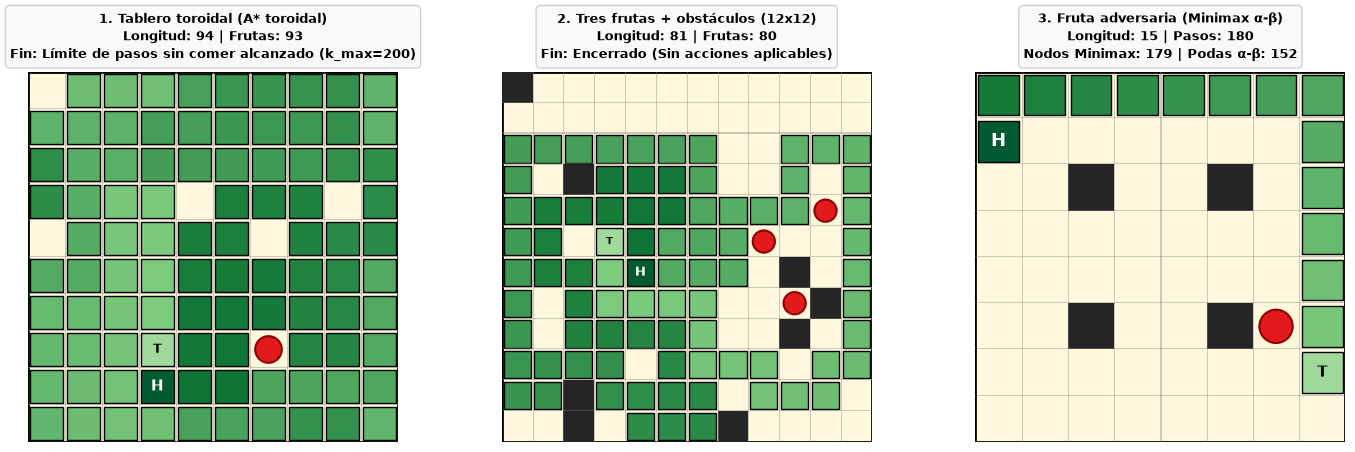

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.8),
                         gridspec_kw={"wspace": 0.28})

# 1. Tablero toroidal: el agente usa la distancia Manhattan toroidal.
env_toro = Snake(tamano=10, semilla=5, toroidal=True, k_max=200)
ag_toro = AgenteSnake(algoritmo="A*", heuristica="manhattan",
                      chequeo_seguridad=True)
jugar_partida(env_toro, ag_toro, semilla=5)
env_toro.render(
    titulo=(f"1. Tablero toroidal (A* toroidal)\n"
            f"Longitud: {env_toro.estado.longitud} | "
            f"Frutas: {env_toro.frutas_comidas}\n"
            f"Fin: {env_toro.causa_fin}"),
    ax=axes[0],
)

# 2. Tres frutas simultáneas y 8 obstáculos fijos en un tablero de
#    12 x 12.
env_m = Snake(tamano=12, semilla=3, num_obstaculos=8, num_frutas=3,
              k_max=200)
ag_m = AgenteSnake(algoritmo="A*", heuristica="manhattan",
                   chequeo_seguridad=True, lambda_riesgo=LAMBDA_RIESGO)
jugar_partida(env_m, ag_m, semilla=3)
env_m.render(
    titulo=(f"2. Tres frutas + obstáculos (12x12)\n"
            f"Longitud: {env_m.estado.longitud} | "
            f"Frutas: {env_m.frutas_comidas}\n"
            f"Fin: {env_m.causa_fin}"),
    ax=axes[1],
)

# 3. Fruta adversaria: un oponente Minimax con poda alfa-beta y
#    profundidad 2 decide dónde aparece cada fruta.
juego_adv = SnakeJuegoAdversario(
    tamano=8, obstaculos=((2, 2), (5, 5), (2, 5), (5, 2)))
oponente = AgenteFrutaAdversaria(game=juego_adv, jugador="fruta", max_lim=2)
env_adv = EnvfromGameAndPl2(juego_adv, oponente)
ag_s = AgenteSnake(algoritmo="A*", heuristica="manhattan",
                   chequeo_seguridad=True)

MAX_PASOS_ADV = 180
est_a = env_adv.reset()
ag_s.states.append(est_a)
pasos_a = 0
while (not juego_adv.es_terminal(env_adv.state)
       and pasos_a < MAX_PASOS_ADV):
    est_a, _, _ = env_adv.step(ag_s.make_decision())
    ag_s.states.append(est_a)
    pasos_a += 1

env_adv.render(
    ax=axes[2],
    titulo=(f"3. Fruta adversaria (Minimax α-β)\n"
            f"Longitud: {env_adv.state.longitud} | Pasos: {pasos_a}\n"
            f"Nodos Minimax: {oponente.nodos_evaluados_minimax} | "
            f"Podas α-β: {oponente.podas_alfa_beta}"),
)
plt.show()

---
## 7. Conclusiones

* Descomponer la partida en subproblemas deterministas permite resolver cada tramo en pocos milisegundos con cualquiera de los seis algoritmos. Como el modelo del entorno es conocido, el agente puede simular un plan antes de ejecutarlo.
* La calidad de la búsqueda no basta por sí sola. Sin el chequeo de seguridad todos los algoritmos se encierran alrededor de las 34 celdas, y con él la serpiente supera en promedio las 90.
* Las diferencias entre algoritmos son menores. A* con $h_1$ ofrece el mejor equilibrio entre optimalidad y nodos expandidos, mientras que la búsqueda avara y el haz son más baratos con una pérdida de calidad mínima.
* La principal limitación aparece al final de la partida, cuando el agente prioriza seguir su cola y termina por $k_{\max}$. Una estrategia de recorrido ordenado para la fase final, como un ciclo hamiltoniano, es la extensión natural de este trabajo.